## Importing Necessary Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import random

import warnings
warnings.filterwarnings('ignore')

In [3]:
!pip install tensorflow

In [4]:
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from tensorflow.keras import Input

In [5]:
!pip install opencv-python

In [6]:
import cv2

## Images to Vectors

In [7]:
import cv2
import numpy as np
import os

# Base folder
base_folder = r'C:\Users\mahit\OneDrive\Desktop\Multi Cancer\Multi Cancer\Brain Cancer'

# Subfolders for each class
brain_glioma_folder = os.path.join(base_folder, 'brain_glioma')
brain_menin_folder = os.path.join(base_folder, 'brain_menin')
brain_tumor_folder = os.path.join(base_folder, 'brain_tumor')

# Function to get full image paths from a folder
def get_image_paths(folder):
    return [os.path.join(folder, filename) 
            for filename in os.listdir(folder) 
            if filename.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'))]

# Function to load and preprocess images
def load_images(image_paths):
    images = []
    for path in image_paths:
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            print(f"Warning: Could not read {path}")
            continue
        img = cv2.resize(img, (224, 224))
        img = img.astype(np.float32) / 255.0
        
        images.append(img)
    return images

# Get image paths
brain_glioma_paths = get_image_paths(brain_glioma_folder)
brain_menin_paths = get_image_paths(brain_menin_folder)
brain_tumor_paths = get_image_paths(brain_tumor_folder)

# Load images
brain_glioma = load_images(brain_glioma_paths)
brain_menin = load_images(brain_menin_paths)
brain_tumor = load_images(brain_tumor_paths)

# Optional: print summary
print(f"Glioma images loaded: {len(brain_glioma)}")
print(f"Menin images loaded: {len(brain_menin)}")
print(f"Tumor images loaded: {len(brain_tumor)}")



Glioma images loaded: 5000
Menin images loaded: 5000
Tumor images loaded: 5000


In [8]:
brain_glioma

[array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]], dtype=float32),
 array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]], dtype=float32),
 array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]], dtype=float32),
 array([[0.        , 0.        , 0.        , ..., 0.00392157, 0.        ,
         0.        ],
        [0.        , 0.        , 0.        , ..., 0.00392157, 0.        ,
         0.        ],
        [0.     

## Data Preprocessing

In [9]:
# Assign labels
brain_glioma_labels = [0] * len(brain_glioma)
brain_menin_labels = [1] * len(brain_menin)
brain_tumor_labels = [2] * len(brain_tumor)

# Combine data and labels
X = np.array(brain_glioma + brain_menin + brain_tumor, dtype=np.float32)[..., np.newaxis]
y = brain_glioma_labels + brain_menin_labels + brain_tumor_labels
y = to_categorical(y, num_classes=3)


In [10]:
X[0][150] #1st picture and 150th row

array([[0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.        ],
       [0.   

In [11]:
from sklearn.model_selection import train_test_split

# Assuming X is (N, 224, 224, 1) and y is one-hot encoded (N, 3)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       # 20% test set
    random_state=42,     # For reproducibility
    shuffle=True         # Shuffle before splitting
)

In [12]:
X_train.shape

(12000, 224, 224, 1)

In [13]:
X_train_1, X_val, y_train_1, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

In [14]:
datagen = ImageDataGenerator(
    rotation_range=20,  
    width_shift_range=0.2,  
    height_shift_range=0.2,  
    shear_range=0.2,  
    zoom_range=0.2,  
    horizontal_flip=True,  
    fill_mode="nearest"
)
datagen.fit(X_train_1)

## Training CNN Model

In [15]:
model = Sequential([
    
    Input(shape=(224, 224, 1)), #Defines input layers in functional API.

    # 3 Convolutional layers (Extracts important features from images (edges, textures, patterns). 
    # Applies filters (kernels) to scan different regions of the image.
    
    # [Maxpooling] - Reduces image size while keeping important features.
    # Picks the largest value from small regions of the image.
    Conv2D(filters=32, kernel_size=(3,3), activation='relu', input_shape=(224,224,3)),
    MaxPooling2D(pool_size=(2,2)),

    Conv2D(filters=64, kernel_size=(3,3), activation='relu', input_shape=(224,224,3)),
    MaxPooling2D(pool_size=(2,2)),

    Conv2D(filters=128, kernel_size=(3,3), activation='relu', input_shape=(224,224,3)),
    MaxPooling2D(pool_size=(2,2)),

    Flatten(),
    Dense(128, activation='relu'),

    # [dropout] - Reduces overfitting by randomly disabling 50% of neurons.
    # This forces the network to learn robust features rather than memorizing training data.
    # Helps generalization by preventing dependency on specific neurons.
    Dropout(0.5),
    Dense(3, activation='softmax')
])

In [16]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 86528)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      11,075,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 11,168,771 (42.61 MB)

 Trainable params: 11,168,771 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [76]:
model.compile(optimizer=Adam(learning_rate=0.001), 
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

In [18]:
import tensorflow as tf

train_dataset = tf.data.Dataset.from_tensor_slices((X_train_1, y_train_1)).batch(32)
val_dataset = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(32)

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    verbose=1
) 

Epoch 1/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 586s 2s/step - accuracy: 0.6517 - loss: 0.7530 - val_accuracy: 0.8175 - val_loss: 0.4930
Epoch 2/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 590s 2s/step - accuracy: 0.8101 - loss: 0.4874 - val_accuracy: 0.8525 - val_loss: 0.4140
Epoch 3/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 567s 2s/step - accuracy: 0.8531 - loss: 0.3764 - val_accuracy: 0.8642 - val_loss: 0.3569
Epoch 4/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 577s 2s/step - accuracy: 0.8903 - loss: 0.2903 - val_accuracy: 0.8662 - val_loss: 0.3607
Epoch 5/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 569s 2s/step - accuracy: 0.9045 - loss: 0.2392 - val_accuracy: 0.8838 - val_loss: 0.3198
Epoch 6/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 604s 2s/step - accuracy: 0.9274 - loss: 0.1816 - val_accuracy: 0.8675 - val_loss: 0.3709
Epoch 7/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 587s 2s/step - accuracy: 0.9363 - loss: 0.1621 - val_accuracy: 0.8963 - val_loss: 0.3335
Epoch 8/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 581s 2s/step - accuracy: 0.9460 - loss: 0.1419 - val_accu

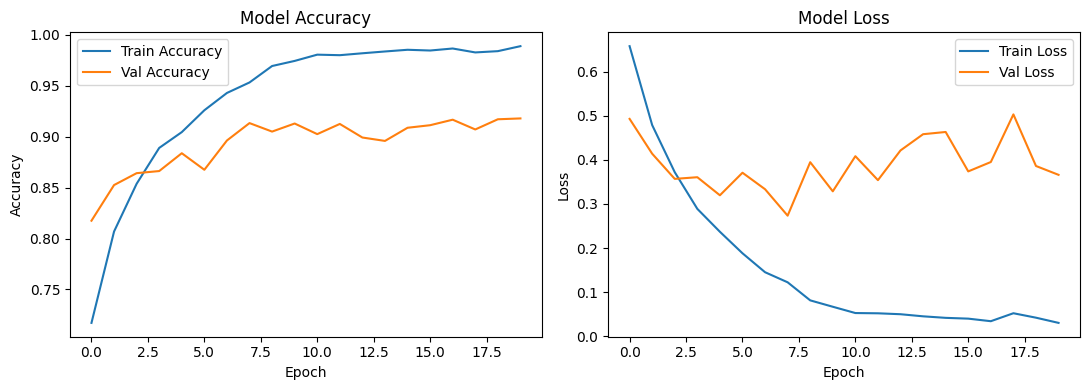

In [19]:

fig, axs = plt.subplots(1, 2, figsize=(11, 4))

# Accuracy subplot
axs[0].plot(history.history['accuracy'], label='Train Accuracy')
axs[0].plot(history.history['val_accuracy'], label='Val Accuracy')
axs[0].set_title('Model Accuracy')
axs[0].set_xlabel('Epoch')
axs[0].set_ylabel('Accuracy')
axs[0].legend()

# Loss subplot
axs[1].plot(history.history['loss'], label='Train Loss')
axs[1].plot(history.history['val_loss'], label='Val Loss')
axs[1].set_title('Model Loss')
axs[1].set_xlabel('Epoch')
axs[1].set_ylabel('Loss')
axs[1].legend()

plt.tight_layout()
plt.show()

## CNN's Activation with respect to Different Parts of the Image

In [125]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout

input_layer = Input(shape=(224, 224, 3))  
x = Conv2D(32, (3, 3), activation='relu', name='conv2d')(input_layer)
x = MaxPooling2D((2, 2), name='max_pooling2d')(x)
x = Conv2D(64, (3, 3), activation='relu', name='conv2d_1')(x)
x = MaxPooling2D((2, 2), name='max_pooling2d_1')(x)
x = Conv2D(128, (3, 3), activation='relu', name='conv2d_2')(x)
x = MaxPooling2D((2, 2), name='max_pooling2d_2')(x)
x = Flatten(name='flatten')(x)
x = Dense(128, activation='relu', name='dense')(x)
x = Dropout(0.5, name='dropout')(x)
output = Dense(3, activation='softmax', name='dense_1')(x)

model = Model(inputs=input_layer, outputs=output)

In [133]:
from tensorflow.keras.preprocessing import image
import numpy as np

# Load and preprocess one image
img_path = r"C:\Users\mahit\OneDrive\Desktop\Multi Cancer\Multi Cancer\Brain Cancer\brain_tumor\brain_tumor_0091.jpg" 
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img) / 255.0 
image = img_array 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step


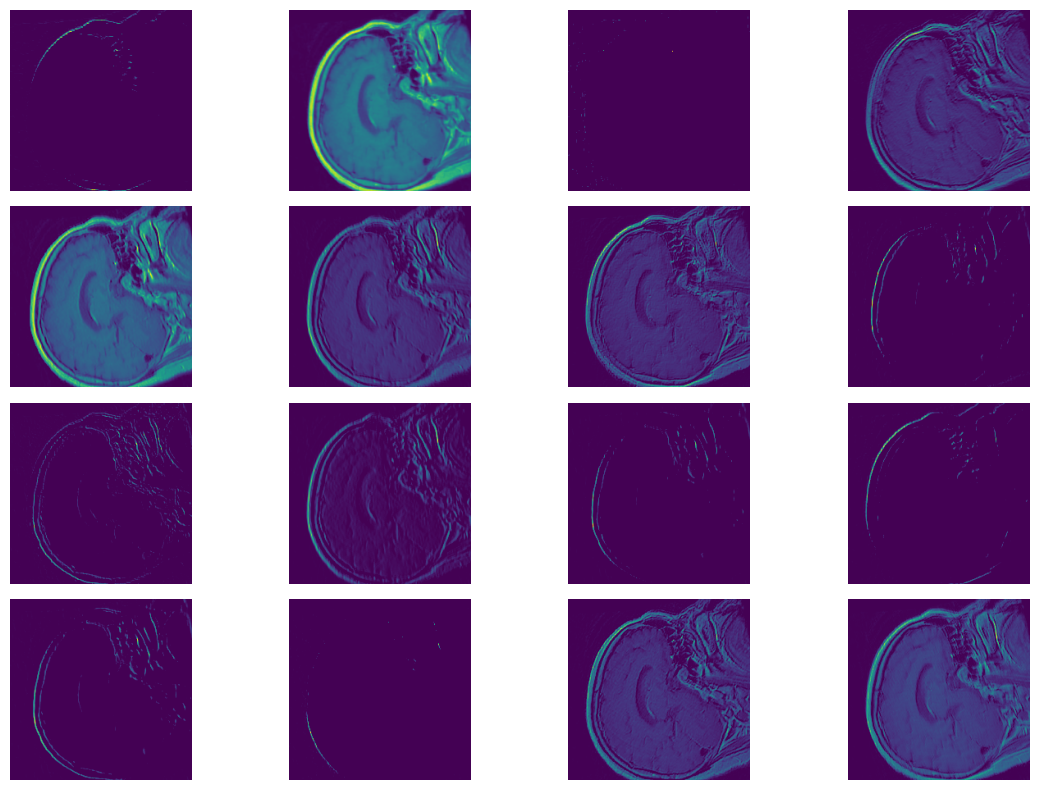

In [137]:
# Creating a sub-model to extract feature maps from 'conv2d_2'
activation_model = Model(inputs=model.input, outputs=model.get_layer('conv2d').output)

image = img 
image_batch = np.expand_dims(image, axis=0)

# Geting feature maps
feature_maps = activation_model.predict(image_batch)

# Visualize first few feature maps
n_features = min(16, feature_maps.shape[-1])  # show up to 16
plt.figure(figsize=(12, 8))
for i in range(n_features):
    plt.subplot(4, 4, i+1)
    plt.imshow(feature_maps[0, :, :, i], cmap='viridis')
    plt.axis('off')
plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step


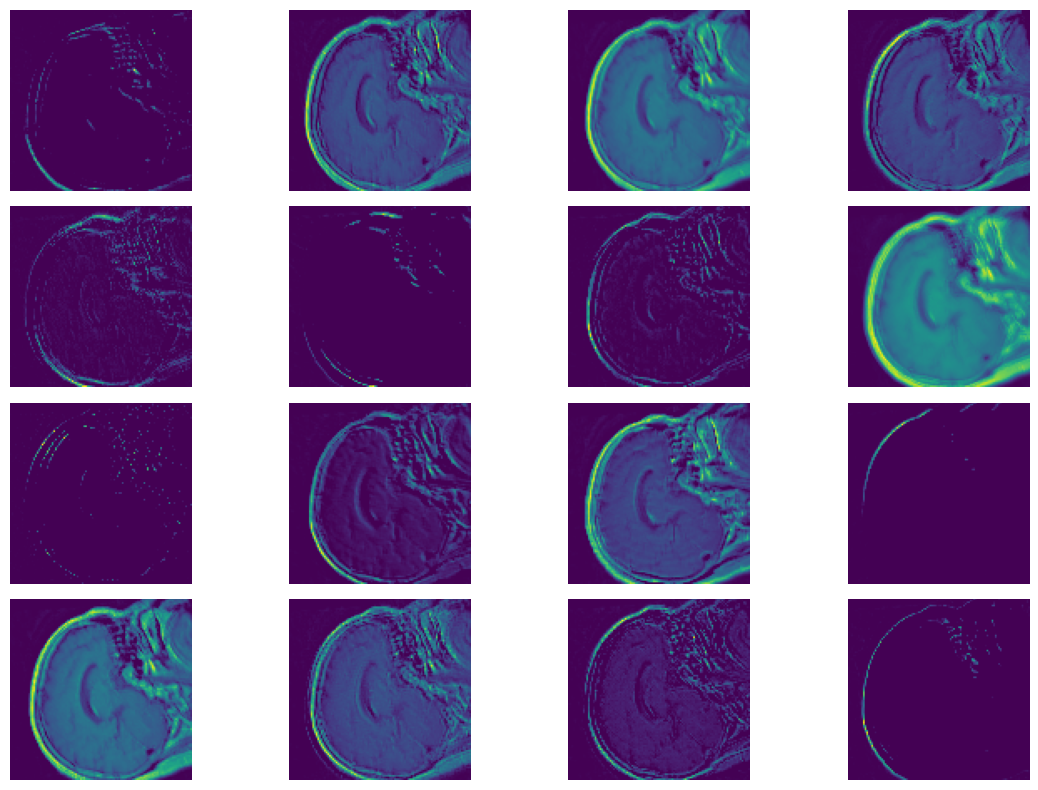

In [139]:
# Creating a sub-model to extract feature maps from 'conv2d_2'
activation_model = Model(inputs=model.input, outputs=model.get_layer('conv2d_1').output)

image = img 
image_batch = np.expand_dims(image, axis=0)

# Geting feature maps
feature_maps = activation_model.predict(image_batch)

# Visualize first few feature maps
n_features = min(16, feature_maps.shape[-1])  # show up to 16
plt.figure(figsize=(12, 8))
for i in range(n_features):
    plt.subplot(4, 4, i+1)
    plt.imshow(feature_maps[0, :, :, i], cmap='viridis')
    plt.axis('off')
plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step


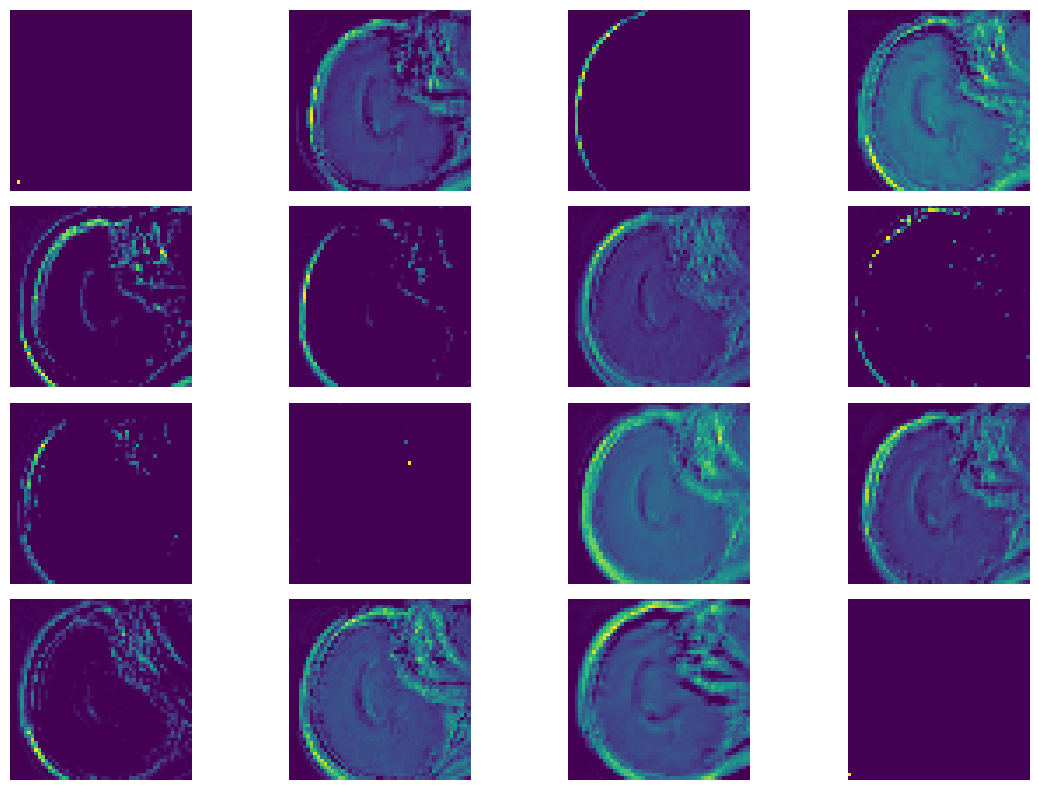

In [141]:
# Creating a sub-model to extract feature maps from 'conv2d_2'
activation_model = Model(inputs=model.input, outputs=model.get_layer('conv2d_2').output)

image = img 
image_batch = np.expand_dims(image, axis=0)

# Getting feature maps
feature_maps = activation_model.predict(image_batch)

# Visualize first few feature maps
n_features = min(16, feature_maps.shape[-1])  # show up to 16
plt.figure(figsize=(12, 8))
for i in range(n_features):
    plt.subplot(4, 4, i+1)
    plt.imshow(feature_maps[0, :, :, i], cmap='viridis')
    plt.axis('off')
plt.tight_layout()
plt.show()

## Test Data 

In [20]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

94/94 ━━━━━━━━━━━━━━━━━━━━ 45s 468ms/step - accuracy: 0.9077 - loss: 0.4179
Test Loss: 0.4258
Test Accuracy: 0.9090


In [36]:
y_pred = model.predict(X_test)

94/94 ━━━━━━━━━━━━━━━━━━━━ 44s 459ms/step


In [40]:
y_pred_labels = np.argmax(y_pred, axis=1)
y_test_labels = np.argmax(y_test, axis=1)  # Only if y_test is one-hot encoded

accuracy = accuracy_score(y_test_labels, y_pred_labels)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.9090


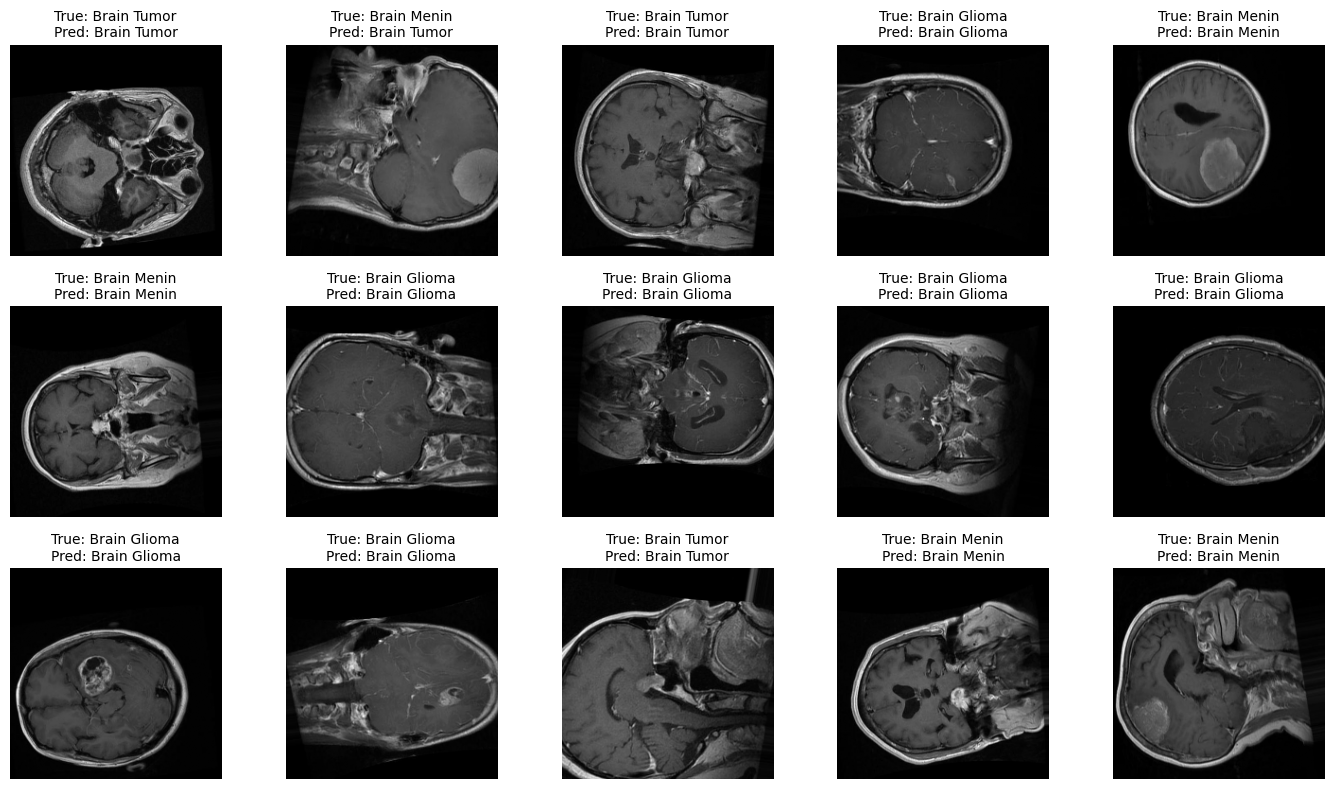

In [68]:
class_names = ['Brain Glioma', 'Brain Menin', 'Brain Tumor']

# Plot images with class names
plt.figure(figsize=(14, 8))
for i in range(15):
    plt.subplot(3,5, i + 1)
    plt.imshow(X_test[i], cmap='gray')
    true_name = class_names[y_true_labels[i]]
    pred_name = class_names[y_pred_labels[i]]
    plt.title(f"True: {true_name}\nPred: {pred_name}", fontsize = 10)
    plt.axis('off')
plt.tight_layout()
plt.show()

75/75 ━━━━━━━━━━━━━━━━━━━━ 33s 440ms/step


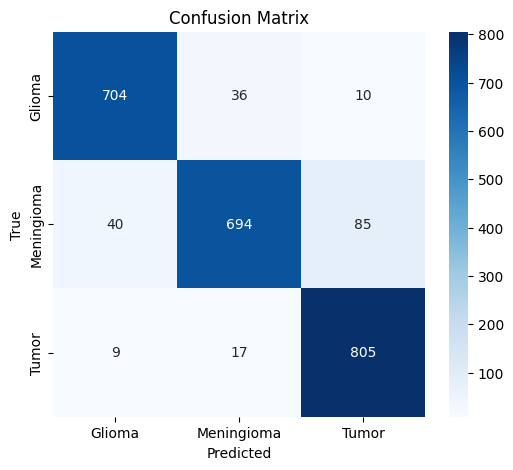

In [97]:
# Predict on validation or test data
y_pred = model.predict(X_val)
y_pred_labels = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_val, axis=1)

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred_labels)

# Plot heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Glioma', 'Meningioma', 'Tumor'],
            yticklabels=['Glioma', 'Meningioma', 'Tumor'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

75/75 ━━━━━━━━━━━━━━━━━━━━ 34s 443ms/step


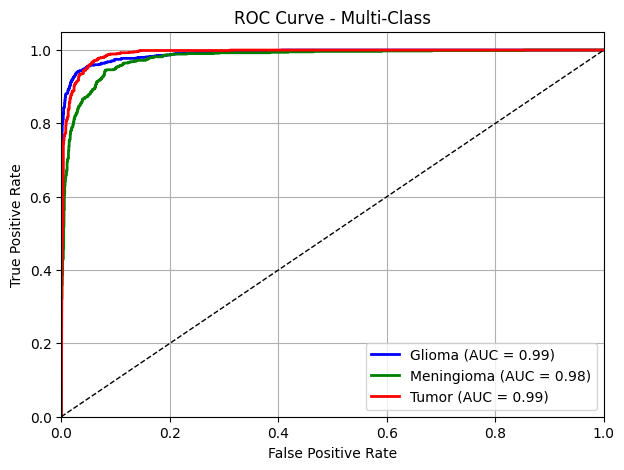

In [78]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
import numpy as np

# Ensure y_true and y_pred are numpy arrays
y_true = np.argmax(y_val, axis=1)
y_score = model.predict(X_val)  # shape: (num_samples, 3)

# Binarize the labels for ROC (one-hot encoding)
y_true_bin = label_binarize(y_true, classes=[0, 1, 2])

# Plot ROC curve for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(3):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot
plt.figure(figsize=(7, 5))
colors = ['blue', 'green', 'red']
class_names = ['Glioma', 'Meningioma', 'Tumor']
for i, color in zip(range(3), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'{class_names[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Multi-Class')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

75/75 ━━━━━━━━━━━━━━━━━━━━ 34s 448ms/step


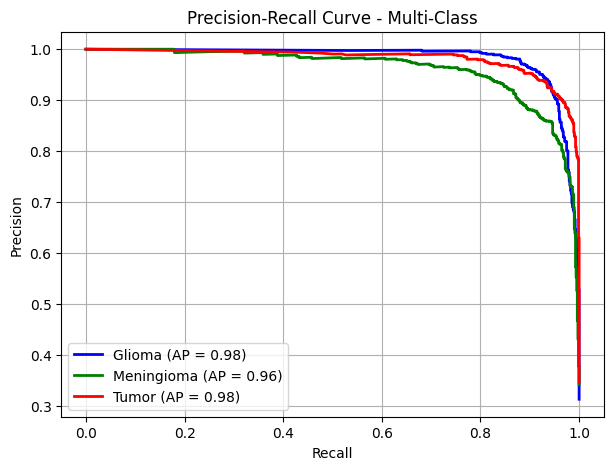

In [79]:
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import numpy as np
# Predict scores
y_score = model.predict(X_val)
y_true = np.argmax(y_val, axis=1)
y_true_bin = label_binarize(y_true, classes=[0, 1, 2])

# Plot precision-recall curve for each class
plt.figure(figsize=(7, 5))
class_names = ['Glioma', 'Meningioma', 'Tumor']
colors = ['blue', 'green', 'red']

for i, color in zip(range(3), colors):
    precision, recall, _ = precision_recall_curve(y_true_bin[:, i], y_score[:, i])
    ap = average_precision_score(y_true_bin[:, i], y_score[:, i])
    plt.plot(recall, precision, color=color, lw=2,
             label=f'{class_names[i]} (AP = {ap:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Multi-Class')
plt.legend(loc='lower left')
plt.grid(True)
plt.show()

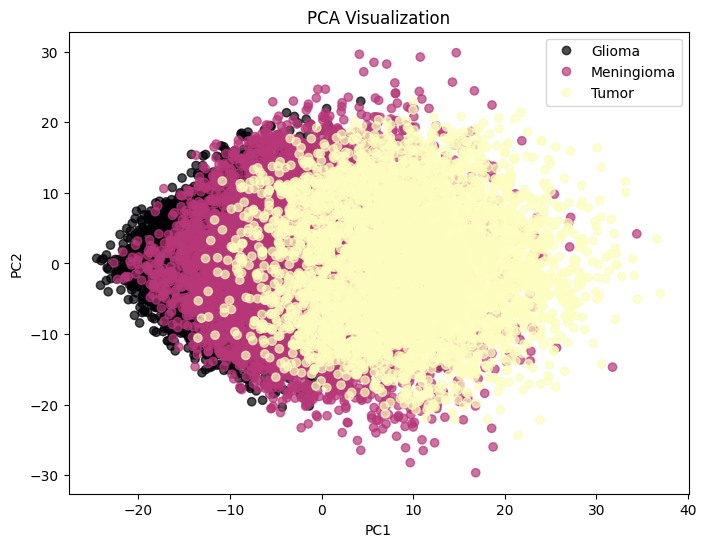

In [70]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

# Flatten images if needed: (num_samples, 224*224)
X_flat = X.reshape(X.shape[0], -1)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_flat)

plt.figure(figsize=(8,6))
scatter = plt.scatter(X_pca[:,0], X_pca[:,1], c=np.argmax(y, axis=1), cmap='magma', alpha=0.7)
plt.legend(handles=scatter.legend_elements()[0], labels=['Glioma', 'Meningioma', 'Tumor'])
plt.title('PCA Visualization')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()


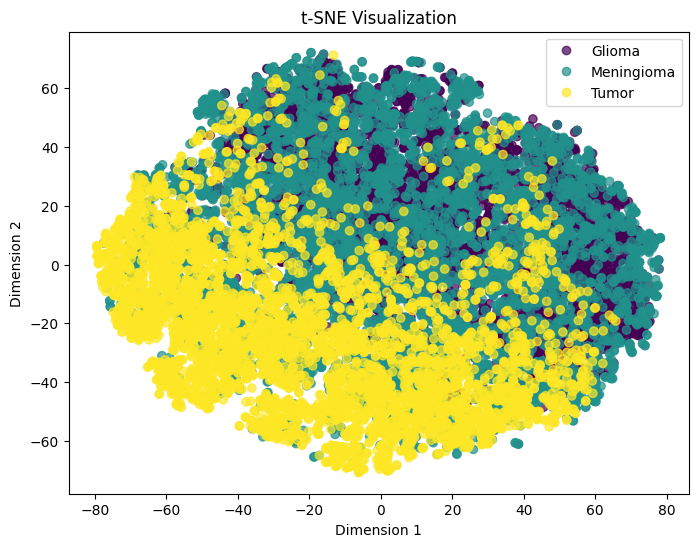

In [72]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_flat)

plt.figure(figsize=(8,6))
scatter = plt.scatter(X_tsne[:,0], X_tsne[:,1], c=np.argmax(y, axis=1), cmap='viridis', alpha=0.7)
plt.legend(handles=scatter.legend_elements()[0], labels=['Glioma', 'Meningioma', 'Tumor'])
plt.title('t-SNE Visualization')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.show()

## Few Mislabelled Data Points

94/94 ━━━━━━━━━━━━━━━━━━━━ 50s 528ms/step


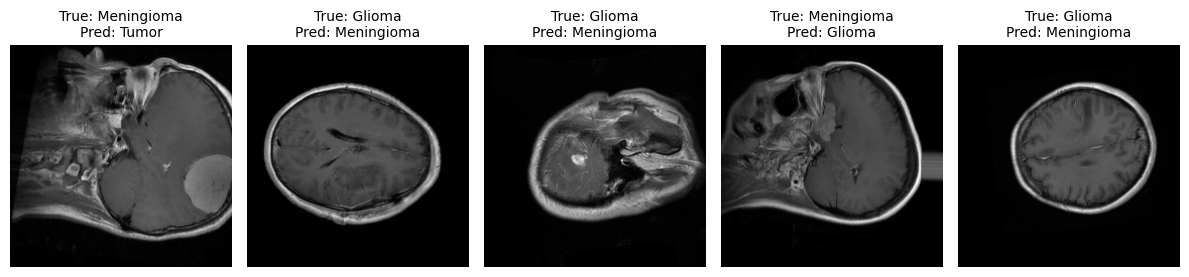

In [109]:
# predict on X_test only
y_pred = model.predict(X_test)
y_pred_labels = np.argmax(y_pred, axis=1)
y_true_labels = np.argmax(y_test, axis=1)

# find misclassified indices
wrong = np.where(y_true_labels != y_pred_labels)[0]

# plot first five misclassified
plt.figure(figsize=(12,6))
for idx, i in enumerate(wrong[:5]):
    plt.subplot(1,5,idx+1)
    plt.imshow(X_test[i], cmap='gray')
    plt.title(f"True: {class_names[y_true_labels[i]]}\nPred: {class_names[y_pred_labels[i]]}", fontsize = 10)
    plt.axis('off')
plt.tight_layout()
plt.show()